# Teaching a RAG system to abstain: thresholds, coverage and selective accuracy

A RAG system should say "not in the documents" when the documents do not hold the answer. This notebook builds that behaviour three ways and measures each on held-out questions: a retrieval-score gate that refuses before calling the model, the generator's own refusals, and an NLI check that withholds answers whose sentences are not supported. You get threshold rules tuned on a dev split and tested on a separate test split, risk-coverage curves for four confidence signals, and the trade-off between answering more questions and answering them correctly.

Data: the [VeriDex RAG corpus](https://www.kaggle.com/datasets/swapnilshukla007/veridex-rag-corpus) dataset (157 questions, 51 of them not answerable from the documents). Answers are generated here by `Qwen2.5-1.5B-Instruct` (Apache 2.0) on a Kaggle T4 GPU; no API keys are used. Run time: about 10 to 15 minutes on a Kaggle T4 GPU (an estimate; most of it is downloading and running the 1.5B generator).

Links: [live app](https://swapnil007-curious.github.io/VeriDex/) · [GitHub repo](https://github.com/Swapnil007-Curious/VeriDex) · paper (link to be added)

Part 4 of the 5-part VeriDex series on building and checking a RAG system.

## Contents

1. Setup
2. Data and splits
3. Retrieval and three confidence signals
4. A retrieval gate that refuses before generation
5. Generating answers with citations
6. Is each answer correct and supported?
7. Risk-coverage curves
8. Abstention policies on the test split
9. What we found

## 1. Setup

Turn on the GPU (Settings, Accelerator, GPU T4) before running. Without a GPU the notebook still runs, but generation with a 1.5B model on a CPU takes well over an hour.

In [1]:
import importlib.util
import subprocess
import sys


def ensure(package: str, module: str) -> None:
    """Install a pinned package only when the environment does not already provide the module."""
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)


ensure("sentence-transformers==6.2.0", "sentence_transformers")

In [2]:
import json
import os
import random
import re
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()  # keep library notices out of the outputs

In [3]:
SEED = 42  # seeds Python, NumPy and PyTorch; also the bootstrap generator
FAST = os.environ.get("VERIDEX_FAST", "0") == "1"  # smoke-test mode for machines without a GPU; leave off on Kaggle
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GENERATOR = "Qwen/Qwen2.5-1.5B-Instruct"  # Apache 2.0; about 3 GB in fp16 on a T4
if FAST and DEVICE == "cpu":
    GENERATOR = "Qwen/Qwen2.5-0.5B-Instruct"  # smaller model, only for CPU smoke tests
EMBED_MODEL = "BAAI/bge-small-en-v1.5"  # the retriever the VeriDex web app runs in the browser
QUERY_INSTRUCTION = "Represent this sentence for searching relevant passages: "  # bge v1.5 query prefix
RERANKER = "cross-encoder/ms-marco-MiniLM-L-6-v2"  # gives a second retrieval confidence signal
NLI_MODEL = "cross-encoder/nli-deberta-v3-base"  # checks support and correctness, as in notebook 3
CONTEXT_BUDGET = 1024  # passage tokens packed into the prompt (bge-small tokenizer counts)
RERANK_N = 20  # candidates rescored by the cross-encoder
MAX_NEW_TOKENS = 200  # answer length cap
GEN_BATCH = 8 if DEVICE == "cuda" else 2  # prompts per generate() call
ENTAIL_THRESHOLD = 0.5  # P(entailment) needed for "supported" and for "correct"
FAST_QUESTIONS = 36  # questions generated in FAST mode (stratified by split and answerability)
N_BOOT = 1000  # bootstrap resamples
COLLECTION_LABELS = {"consumer_rules": "Consumer rules", "cs_ai": "CS / AI textbooks"}
DOMAINS = {"consumer_rules": "Indian consumer protection law, from the Consumer Protection Rules",
           "cs_ai": "computer science, machine learning and Git, from open textbooks"}

# Okabe-Ito colours, distinguishable with the common forms of colour blindness
COLOURS = {"answerable": "#0072B2", "unanswerable": "#D55E00", "top-1 cosine": "#56B4E9", "rerank score": "#009E73",
           "answer log-prob": "#E69F00", "NLI support": "#CC79A7", "random": "#999999", "oracle": "#000000"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})


def set_seed(seed: int = SEED) -> None:
    """Seed every random number generator the notebook touches."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def takeaway(text: str) -> None:
    """Show the one-line conclusion under a plot."""
    display(Markdown(f"> {text}"))


set_seed()
NOTEBOOK_START = time.time()
print(f"device: {DEVICE}, generator: {GENERATOR}, FAST={FAST}")

device: cpu, generator: Qwen/Qwen2.5-0.5B-Instruct, FAST=True


## 2. Data and splits

Every question has a fixed dev or test label, computed from a hash of its id in the VeriDex repository. Thresholds are chosen on dev and reported on test, so the test numbers are not tuned to the test questions.

In [4]:
def find_data_dir() -> Path:
    """Locate the veridex-rag-corpus dataset under /kaggle/input (or VERIDEX_DATA_DIR when run elsewhere)."""
    if os.environ.get("VERIDEX_DATA_DIR"):
        return Path(os.environ["VERIDEX_DATA_DIR"])
    for manifest in Path("/kaggle/input").glob("**/MANIFEST.json"):
        if json.loads(manifest.read_text(encoding="utf-8")).get("dataset") == "veridex-rag-corpus":
            return manifest.parent
    raise FileNotFoundError("Add the veridex-rag-corpus dataset to this notebook (Add Input).")


def read_jsonl(path: Path) -> list[dict]:
    """Read a JSON-lines file into a list of dicts."""
    with open(path, encoding="utf-8") as fh:
        return [json.loads(line) for line in fh if line.strip()]


DATA_DIR = find_data_dir()
WORK_DIR = Path(os.environ.get("VERIDEX_WORK_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)

texts = {p.stem: p.read_text(encoding="utf-8") for p in (DATA_DIR / "text").glob("*.txt")}
questions = read_jsonl(DATA_DIR / "questions" / "questions.jsonl")
chunks = {c: read_jsonl(DATA_DIR / "chunks" / c / "structural.jsonl") for c in COLLECTION_LABELS}
qdf = pd.DataFrame(questions)
pd.crosstab([qdf.collection, qdf.split], qdf.answerable.map({True: "answerable", False: "unanswerable"}), margins=True)

answerable            answerable  unanswerable  All
collection     split                               
consumer_rules dev            14            14   28
               test           32            17   49
cs_ai          dev            20             4   24
               test           40            16   56
All                          106            51  157

In [5]:
unans = qdf[~qdf.answerable].groupby("collection").head(3)[["collection", "question", "gold_answer"]]
unans.style.hide(axis="index")

collection,question,gold_answer
consumer_rules,What rate of GST applies to services supplied through a marketplace e-commerce entity?,Not in the corpus: the E-Commerce Rules only define GSTIN and require showing applicable tax; no GST rate is specified.
consumer_rules,What's the current stamp duty for a residential property in Karnataka?,"Not in the corpus: it asks about fees that apply only in a particular state, which the Consumer Protection Act, 2019 and its four Rules do not cover."
consumer_rules,How do I contact the consumer helpline in Kerala?,"Not in the corpus: it asks about procedures of a particular state government, which the Consumer Protection Act, 2019 and its four Rules do not cover."
cs_ai,What's the difference between a deployment and a service in Kubernetes?,"Not in the corpus: it asks about Kubernetes and container orchestration, which the selected chapters of the three textbooks do not cover."
cs_ai,What are the main challenges in maintaining qubit coherence for quantum computing?,"Not in the corpus: it asks about quantum computing, which the selected chapters of the three textbooks do not cover."
cs_ai,What are the key differences between Q-learning and Deep Q-Networks?,"Not in the corpus: it asks about reinforcement learning algorithms, which the selected chapters of the three textbooks do not cover."


The unanswerable questions ask about things near the documents' topics that the documents do not cover. That makes them harder to spot than off-topic chat, and it is why a single similarity threshold is not enough.

## 3. Retrieval and three confidence signals

Retrieval follows the VeriDex web app: structure-aware chunks, `bge-small` embeddings, cosine similarity. Each question gets three retrieval-side signals: the top-1 cosine, the gap between the first and second cosine, and the highest cross-encoder score among the top 20. The prompt context is the dense ranking packed until 1,024 tokens are used.

In [6]:
from sentence_transformers import CrossEncoder, SentenceTransformer

embedder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
reranker = CrossEncoder(RERANKER, device=DEVICE)


def encode(texts: list, query: bool = False) -> np.ndarray:
    """L2-normalised bge-small embeddings; queries get the instruction prefix."""
    inputs = [QUERY_INSTRUCTION + t for t in texts] if query else texts
    return embedder.encode(inputs, batch_size=32, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)


def pack(ranked: list, coll: str, budget: int = CONTEXT_BUDGET) -> list:
    """Chunk indices in rank order until the next one would exceed the token budget."""
    out, used = [], 0
    for i in ranked:
        n = chunks[coll][i]["n_tokens"]
        if used + n > budget:
            break
        out.append(i)
        used += n
    return out


corpus_vecs = {c: encode([x["text"] for x in chunks[c]]) for c in COLLECTION_LABELS}
qvecs = encode([q["question"] for q in questions], query=True)
records = []
for q, qv in zip(questions, qvecs):
    coll = q["collection"]
    scores = corpus_vecs[coll] @ qv
    ranked = [int(i) for i in np.lexsort((np.arange(len(scores)), -scores))[:50]]
    rr = reranker.predict([(q["question"], chunks[coll][i]["text"]) for i in ranked[:RERANK_N]], show_progress_bar=False)
    records.append({**q, "context": pack(ranked, coll), "top-1 cosine": float(scores[ranked[0]]),
                    "cosine margin": float(scores[ranked[0]] - scores[ranked[1]]), "rerank score": float(np.max(rr))})
df = pd.DataFrame(records)
df.groupby(["collection", "answerable"])[["top-1 cosine", "cosine margin", "rerank score"]].mean().round(3)

top-1 cosine  cosine margin  rerank score
collection     answerable                                           
consumer_rules False              0.623          0.013        -7.606
               True               0.725          0.030         1.736
cs_ai          False              0.684          0.011        -4.420
               True               0.782          0.028         2.574

How well does each signal separate answerable from unanswerable questions, before any threshold is chosen? AUROC is the probability that a random answerable question scores higher than a random unanswerable one (0.5 is chance).

In [7]:
def auroc(pos, neg) -> float:
    """P(score of a positive > score of a negative), ties counted half (Mann-Whitney U)."""
    pos, neg = np.asarray(pos)[:, None], np.asarray(neg)[None, :]
    return float((pos > neg).mean() + 0.5 * (pos == neg).mean())


SIGNALS_RET = ["top-1 cosine", "cosine margin", "rerank score"]
auc = pd.DataFrame({COLLECTION_LABELS[c]: {s: auroc(df[(df.collection == c) & df.answerable][s], df[(df.collection == c) & ~df.answerable][s])
                                           for s in SIGNALS_RET} for c in COLLECTION_LABELS})
auc.style.format("{:.3f}")

,Consumer rules,CS / AI textbooks
top-1 cosine,0.905,0.879
cosine margin,0.611,0.739
rerank score,0.953,0.917


## 4. A retrieval gate that refuses before generation

The cheapest abstention rule never calls the model: if the best passage is not similar enough to the question, say there is not enough evidence. Two ways to pick the threshold on dev, per collection:

- F1 rule: the threshold that maximises F1 for detecting unanswerable questions (used by the VeriDex research pipeline);
- percentile rule: the 5th percentile of the top-1 cosine of answerable dev questions, rounded down to two decimals, so about 95% of in-scope questions pass (used by the VeriDex web app).

In [8]:
def gate_metrics(scores, answerable, threshold: float) -> dict:
    """Abstain when score < threshold; 'unanswerable' is the positive class."""
    s, a = np.asarray(scores), np.asarray(answerable, dtype=bool)
    abstain = s < threshold
    tp, fp, fn = int((abstain & ~a).sum()), int((abstain & a).sum()), int((~abstain & ~a).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return {"threshold": threshold, "correct refusal": rec, "false abstention": fp / max(a.sum(), 1),
            "precision": prec, "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0}


def f1_threshold(scores, answerable) -> float:
    """Distinct score that maximises F1 for unanswerable detection; ties go to the lower threshold."""
    best = max(sorted(set(np.round(scores, 6))), key=lambda t: (gate_metrics(scores, answerable, t)["f1"], -t))
    return float(best)


def percentile_threshold(scores, answerable, p: float = 5.0) -> float:
    """5th percentile of answerable scores, rounded down to two decimals."""
    return float(np.floor(np.percentile(np.asarray(scores)[np.asarray(answerable, dtype=bool)], p) * 100) / 100)


rows, thresholds = [], {}
for coll in COLLECTION_LABELS:
    dev = df[(df.collection == coll) & (df.split == "dev")]
    test = df[(df.collection == coll) & (df.split == "test")]
    for rule, fn in [("F1 rule", f1_threshold), ("percentile rule", percentile_threshold)]:
        t = fn(dev["top-1 cosine"].values, dev.answerable.values)
        thresholds[(coll, rule)] = t
        rows.append({"collection": COLLECTION_LABELS[coll], "rule": rule, "dev n": len(dev), "test n": len(test),
                     **gate_metrics(test["top-1 cosine"].values, test.answerable.values, t)})
gate = pd.DataFrame(rows)
gate.style.format({"threshold": "{:.3f}", "correct refusal": "{:.0%}", "false abstention": "{:.0%}", "precision": "{:.2f}", "f1": "{:.2f}"}).hide(axis="index")

collection,rule,dev n,test n,threshold,correct refusal,false abstention,precision,f1
Consumer rules,F1 rule,28,49,0.751,100%,62%,0.46,0.63
Consumer rules,percentile rule,28,49,0.620,71%,3%,0.92,0.80
CS / AI textbooks,F1 rule,24,56,0.726,69%,20%,0.58,0.63
CS / AI textbooks,percentile rule,24,56,0.740,75%,22%,0.57,0.65


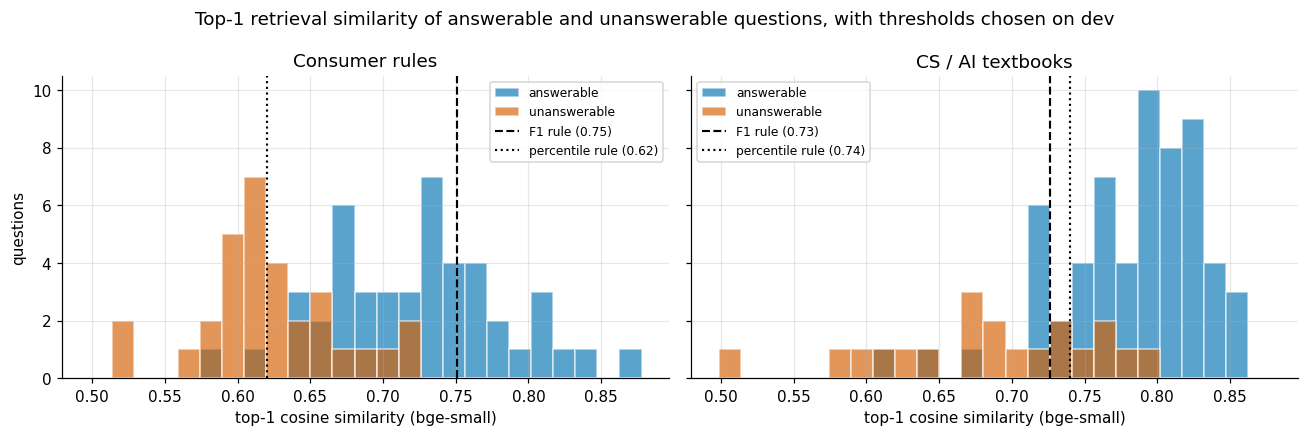

> On the test split the percentile rule refuses 71% of unanswerable consumer-rules questions and 75% of unanswerable textbook questions, while blocking 3% and 22% of answerable ones.

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, coll in zip(axes, COLLECTION_LABELS):
    sub = df[df.collection == coll]
    bins = np.linspace(df["top-1 cosine"].min() - 0.01, df["top-1 cosine"].max() + 0.01, 26)
    for label, mask in [("answerable", sub.answerable), ("unanswerable", ~sub.answerable)]:
        ax.hist(sub[mask]["top-1 cosine"], bins=bins, alpha=0.65, color=COLOURS[label], label=label, edgecolor="white")
    for rule, ls in [("F1 rule", "--"), ("percentile rule", ":")]:
        ax.axvline(thresholds[(coll, rule)], color="black", ls=ls, lw=1.4, label=f"{rule} ({thresholds[(coll, rule)]:.2f})")
    ax.set_title(COLLECTION_LABELS[coll])
    ax.set_xlabel("top-1 cosine similarity (bge-small)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("questions")
fig.suptitle("Top-1 retrieval similarity of answerable and unanswerable questions, with thresholds chosen on dev")
plt.tight_layout()
plt.show()
g = gate.set_index(["collection", "rule"])
takeaway(f"On the test split the percentile rule refuses {g.loc[('Consumer rules', 'percentile rule'), 'correct refusal']:.0%} of unanswerable consumer-rules questions "
         f"and {g.loc[('CS / AI textbooks', 'percentile rule'), 'correct refusal']:.0%} of unanswerable textbook questions, while blocking "
         f"{g.loc[('Consumer rules', 'percentile rule'), 'false abstention']:.0%} and {g.loc[('CS / AI textbooks', 'percentile rule'), 'false abstention']:.0%} of answerable ones.")

## 5. Generating answers with citations

The prompt is adapted from the VeriDex synthesizer: numbered passages, a rule to end every sentence with its passage labels, and an explicit way out, `NOT FOUND`, when the passages do not contain the answer. Decoding is greedy, so a rerun on the same hardware gives the same text. The mean log-probability of the generated tokens is kept as a fourth confidence signal.

In [10]:
SYSTEM_PROMPT = """You answer questions about {domain}. You are given numbered passages and one question.

Rules:
1. Use ONLY information stated in the passages. Do not add facts from memory.
2. Write plain sentences. End every sentence with the label of the passage that supports it, in square brackets, like this: "Water boils at 100 degrees Celsius at sea level [C3]."
3. Copy numbers, names and time limits exactly as the passages write them.
4. Keep the answer short: one to three sentences.
5. If the passages do not contain the answer, reply with exactly: NOT FOUND"""


def build_messages(rec: dict) -> list:
    """Chat messages with the labelled passages and the question."""
    coll = rec["collection"]
    blocks = [f"[C{j}] Source: {chunks[coll][i]['heading_path']}\n{texts[chunks[coll][i]['doc_id']][chunks[coll][i]['char_start']:chunks[coll][i]['char_end']]}"
              for j, i in enumerate(rec["context"], start=1)]
    user = "Passages:\n\n" + "\n\n".join(blocks) + f"\n\nQuestion: {rec['question']}"
    return [{"role": "system", "content": SYSTEM_PROMPT.format(domain=DOMAINS[coll])}, {"role": "user", "content": user}]


def is_refusal(answer: str) -> bool:
    """The model abstained: it starts with NOT FOUND, or says nothing else of substance (under 60 characters)."""
    head = re.sub(r"^[\W_]+", "", answer).upper()
    return head.startswith("NOT FOUND") or ("NOT FOUND" in answer.upper() and len(answer) < 60)


if FAST:  # stratified subset: equal shares of each split x answerability cell
    pick = df.groupby(["split", "answerable"], group_keys=False).apply(
        lambda g: g.sample(min(len(g), FAST_QUESTIONS // 4), random_state=SEED))
    gen_df = df.loc[sorted(pick.index)].copy()
else:
    gen_df = df.copy()
print(f"generating answers for {len(gen_df)} of {len(df)} questions")

generating answers for 36 of 157 questions


In [11]:
import transformers
from packaging.version import Version
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig

gen_tok = AutoTokenizer.from_pretrained(GENERATOR, padding_side="left")
# transformers 4.56 renamed torch_dtype to dtype; pass whichever this version understands
dtype_key = "dtype" if Version(transformers.__version__) >= Version("4.56") else "torch_dtype"
gen_model = AutoModelForCausalLM.from_pretrained(
    GENERATOR, **{dtype_key: torch.float16 if DEVICE == "cuda" else torch.float32}).to(DEVICE).eval()
STOP_IDS = sorted({gen_tok.convert_tokens_to_ids(t) for t in ("<|im_end|>", "<|endoftext|>")} | {gen_tok.eos_token_id})
gen_config = GenerationConfig(max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=gen_tok.pad_token_id,
                              eos_token_id=STOP_IDS, output_scores=True, return_dict_in_generate=True)


@torch.no_grad()
def generate(batch: list) -> list:
    """Greedy answers and the mean log-probability of their tokens for a batch of records."""
    prompts = [gen_tok.apply_chat_template(build_messages(r), tokenize=False, add_generation_prompt=True) for r in batch]
    enc = gen_tok(prompts, return_tensors="pt", padding=True).to(DEVICE)
    out = gen_model.generate(**enc, generation_config=gen_config)
    new = out.sequences[:, enc["input_ids"].shape[1]:]
    # log-probability of each chosen token, one step at a time (stacking full-vocabulary scores costs ~1 GB per batch)
    tok_logp = torch.stack([torch.log_softmax(s.float(), dim=-1).gather(1, new[:, j:j + 1]).squeeze(1)
                            for j, s in enumerate(out.scores)], dim=1).cpu()
    results = []
    for b in range(len(batch)):
        ids = new[b].tolist()
        n = next((j for j, t in enumerate(ids) if t in STOP_IDS), len(ids))
        n = max(n, 1)
        results.append((gen_tok.decode(ids[:n], skip_special_tokens=True).strip(), float(tok_logp[b, :n].mean())))
    return results


t0 = time.time()
outputs = []
recs = gen_df.to_dict("records")
for k in range(0, len(recs), GEN_BATCH):
    outputs += generate(recs[k:k + GEN_BATCH])
gen_df["answer"] = [o[0] for o in outputs]
gen_df["answer log-prob"] = [o[1] for o in outputs]
gen_df["model abstained"] = gen_df.answer.map(is_refusal)
print(f"generated {len(recs)} answers in {(time.time() - t0) / 60:.1f} min on {DEVICE}")
gen_model = None  # free the GPU memory for the NLI model
if DEVICE == "cuda":
    torch.cuda.empty_cache()
gen_df[["collection", "answerable", "question", "answer"]].head(6).style.hide(axis="index")

generated 36 answers in 11.9 min on cpu


collection,answerable,question,answer
consumer_rules,False,What rate of GST applies to services supplied through a marketplace e-commerce entity?,GST is applied to services supplied through a marketplace e-commerce entity at a rate of 18%.
consumer_rules,True,What should a memorandum filed under sub-rule (1) include according to rule 14(2)?,"The memorandum should preferably be typed, or be in legible handwriting, and shall set forth concisely under distinct heads, the grounds of appeal without any argument or narrative and such grounds shall be numbered consecutively."
consumer_rules,True,What steps does the National Commission take if a respondent doesn't show up for a hearing?,The National Commission decides the complaint ex-parte on the merits of the case.
consumer_rules,True,How does the e-commerce platform ensure the prices of goods and services are not unjustified?,"[Sub-rule (11)] The e-commerce platform ensures that prices are not unjustified by requiring sellers to provide accurate and transparent descriptions, images, and other content regarding goods or services on their platform."
consumer_rules,True,"If I settle a complaint through mediation, how do I get my application fee back?","To get your application fee back, you should follow these steps: 1. **Check Your Receipt**: Ensure you have received your application fee correctly. It's important to verify that all necessary forms and documents were submitted properly. 2. **Review the Settlement**: Look at the details provided in the mediation agreement. This will help you understand what was agreed upon and how much you owe. 3. **Contact the Mediator**: Reach out to the mediator directly to discuss your situation. They can provide guidance on how to proceed with settling the matter. 4. **Seek Legal Advice**: Consult with a lawyer experienced in consumer disputes to ensure you understand your rights fully and navigate the legal process effectively. 5. **Follow Up**: After resolving the dispute, contact the mediator again to confirm that the settlement has been finalized and that you have received your refund. By following these steps, you can successfully resolve your issue through mediation and recover your application fee."
consumer_rules,True,What does the term 'Act' refer to in the text?,"The term 'Act' refers to the Consumer Protection Act, 2019 (35 of 2019)."


## 6. Is each answer correct and supported?

Two NLI checks, the same as in notebook 3. An answer to an answerable question is correct when it entails the gold answer, or, for numeric questions, when every number in the gold answer appears in it. Any answer to an unanswerable question is wrong; refusing it is right. Support: each sentence is checked against the passages it cites, and the answer's NLI support score is the mean over its sentences (0 for a sentence without a valid citation).

In [12]:
nli = CrossEncoder(NLI_MODEL, device=DEVICE)
ENTAIL = next(int(i) for i, lab in nli.model.config.id2label.items() if "entail" in lab.lower())
CITE_RE = re.compile(r"\[\s*[Cc]\s*\d+(?:\s*[,;]\s*(?:[Cc]\s*)?\d+)*\s*\]")


def entail(pairs: list) -> np.ndarray:
    """P(entailment) for (premise, hypothesis) pairs."""
    if not pairs:
        return np.zeros(0)
    probs = nli.predict(pairs, apply_softmax=True, batch_size=16, show_progress_bar=False)
    return np.asarray(probs).reshape(len(pairs), -1)[:, ENTAIL]


def sentences_with_labels(answer: str) -> list:
    """(sentence without tags, cited label numbers) for each sentence of an answer."""
    parts = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9\[(])|(?<=\])\s+(?=[A-Z])", answer.strip())
    out = []
    for p in parts:
        nums = [int(n) for g in CITE_RE.findall(p) for n in re.findall(r"\d+", g)]
        text = re.sub(r"\s+", " ", CITE_RE.sub("", p)).strip()
        if text:
            out.append((text, nums))
    return out


def numbers(text: str) -> set:
    return {n.replace(",", "") for n in re.findall(r"\d[\d,]*(?:\.\d+)?", text)}


def check(rec: dict) -> dict:
    """Correctness and NLI support of one generated answer."""
    if rec["model abstained"]:
        return {"correct": False, "NLI support": np.nan, "p_correct": np.nan}
    coll = rec["collection"]
    passages = [f"{chunks[coll][i]['heading_path']}\n{texts[chunks[coll][i]['doc_id']][chunks[coll][i]['char_start']:chunks[coll][i]['char_end']]}"
                for i in rec["context"]]
    support = []
    for text, nums in sentences_with_labels(rec["answer"]):
        valid = [passages[n - 1] for n in nums if 1 <= n <= len(passages)]
        support.append(float(entail([(p, text) for p in valid]).max()) if valid else 0.0)
    clean = re.sub(r"\s+", " ", CITE_RE.sub("", rec["answer"])).strip()
    if not rec["answerable"]:
        return {"correct": False, "NLI support": float(np.mean(support)) if support else 0.0, "p_correct": np.nan}
    p = float(entail([(clean, rec["gold_answer"])])[0])
    gold_nums = numbers(rec["gold_answer"])
    numeric_ok = rec["type"] == "numeric" and bool(gold_nums) and gold_nums <= numbers(clean)
    return {"correct": p >= ENTAIL_THRESHOLD or numeric_ok, "NLI support": float(np.mean(support)) if support else 0.0, "p_correct": p}


t0 = time.time()
gen_df = gen_df.join(pd.DataFrame([check(r) for r in gen_df.to_dict("records")], index=gen_df.index))
print(f"NLI checks took {time.time() - t0:.0f} s")
gen_df["outcome"] = np.select(
    [gen_df["model abstained"] & ~gen_df.answerable, gen_df["model abstained"], ~gen_df.answerable, gen_df.correct],
    ["correct refusal", "false abstention", "answered an unanswerable question", "correct answer"], "wrong answer")
pd.crosstab(gen_df.collection, gen_df.outcome, margins=True)

NLI checks took 21 s


outcome,answered an unanswerable question,correct answer,correct refusal,false abstention,wrong answer,All
collection,,,,,,
consumer_rules,2,3,9,1,4,19
cs_ai,0,1,7,1,8,17
All,2,4,16,2,12,36


## 7. Risk-coverage curves

Suppose the system answers only when a confidence signal is above some threshold. Lowering the threshold answers more questions (coverage) but lets in more wrong answers. A risk-coverage curve plots the accuracy of the answered questions against coverage as the threshold sweeps; a good signal keeps accuracy high as coverage grows. Questions the model itself refused stay refused. "Random" ranks questions by chance and "oracle" puts every correct answer first.

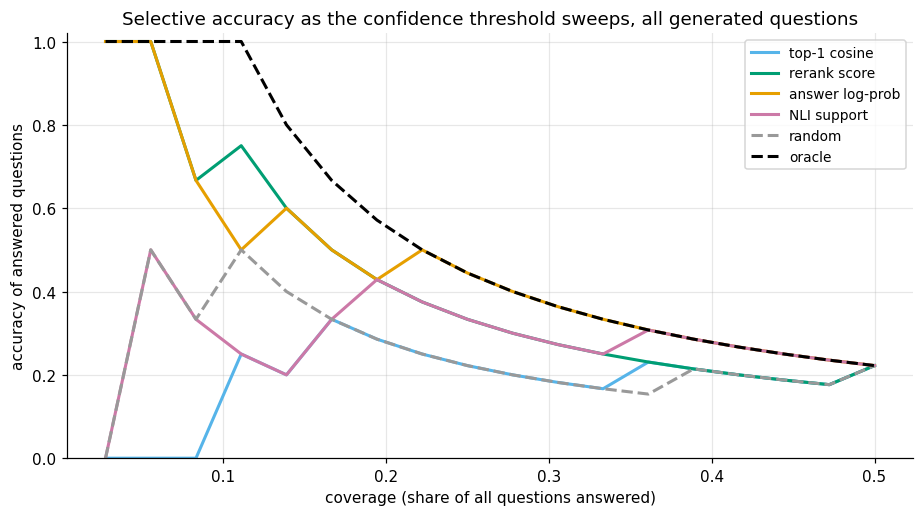

> Ranked by area under the curve: answer log-prob (0.214), rerank score (0.197), NLI support (0.140), top-1 cosine (0.089); random ordering gives 0.123 and the oracle 0.251.

In [13]:
SIGNALS = ["top-1 cosine", "rerank score", "answer log-prob", "NLI support"]
trapezoid = getattr(np, "trapezoid", None) or np.trapz  # NumPy 2 renamed trapz


def selective_curve(frame: pd.DataFrame, signal: str | None) -> tuple:
    """Coverage and selective accuracy when answering the most confident questions first."""
    answered = frame[~frame["model abstained"]]
    if signal is None:  # oracle
        order = answered.correct.sort_values(ascending=False, kind="stable").index
    elif signal == "random":
        order = answered.sample(frac=1.0, random_state=SEED).index
    else:
        order = answered[signal].fillna(-np.inf).sort_values(ascending=False, kind="stable").index
    correct = answered.loc[order, "correct"].values.astype(float)
    k = np.arange(1, len(correct) + 1)
    return k / len(frame), np.cumsum(correct) / k


def plot_curves(ax, frame: pd.DataFrame, big: bool = False) -> dict:
    """Draw the risk-coverage curves; returns the area under each accuracy-coverage curve."""
    areas = {}
    for name in SIGNALS + ["random", "oracle"]:
        cov, acc = selective_curve(frame, None if name == "oracle" else name)
        areas[name] = float(trapezoid(acc, cov)) if len(cov) > 1 else float("nan")
        ax.plot(cov, acc, color=COLOURS[name], lw=3 if big else 2, ls="--" if name in ("random", "oracle") else "-", label=name)
    ax.set_xlabel("coverage (share of all questions answered)")
    ax.set_ylabel("accuracy of answered questions")
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=13 if big else 9)
    return areas


fig, ax = plt.subplots(figsize=(8.5, 4.8))
areas = plot_curves(ax, gen_df)
ax.set_title("Selective accuracy as the confidence threshold sweeps, all generated questions")
plt.tight_layout()
plt.show()
ranked = sorted(SIGNALS, key=lambda s: -areas[s])
takeaway(f"Ranked by area under the curve: {', '.join(f'{s} ({areas[s]:.3f})' for s in ranked)}; random ordering gives {areas['random']:.3f} "
         f"and the oracle {areas['oracle']:.3f}.")

## 8. Abstention policies on the test split

Now combine the pieces into policies and evaluate them on test questions only. Each threshold is tuned on dev to maximise overall accuracy (correct answers plus correct refusals, over all questions).

- model alone: refuse only when the generator writes NOT FOUND;
- retrieval gate: also refuse when the top-1 cosine is below the dev-tuned threshold for that collection (no generation needed for those);
- NLI guard: also refuse when the answer's NLI support is below the dev-tuned threshold;
- gate and guard: both.

In [14]:
def apply_policy(frame: pd.DataFrame, gate_t: dict | None, guard_t: float | None) -> pd.Series:
    """True where the system abstains under a policy."""
    abstain = frame["model abstained"].copy()
    if gate_t is not None:
        abstain |= frame["top-1 cosine"] < frame.collection.map(gate_t)
    if guard_t is not None:
        abstain |= frame["NLI support"].fillna(0) < guard_t
    return abstain


def policy_scores(frame: pd.DataFrame, abstain: pd.Series) -> dict:
    """Overall accuracy, coverage, selective accuracy and the two abstention rates."""
    right = np.where(abstain, ~frame.answerable, frame.answerable & frame.correct)
    answered = ~abstain
    return {"overall accuracy": right.mean(), "coverage": answered.mean(),
            "selective accuracy": (frame.answerable & frame.correct)[answered].mean() if answered.any() else np.nan,
            "correct refusal": abstain[~frame.answerable].mean() if (~frame.answerable).any() else np.nan,
            "false abstention": abstain[frame.answerable].mean() if frame.answerable.any() else np.nan}


dev_df, test_df = gen_df[gen_df.split == "dev"], gen_df[gen_df.split == "test"]


def tune_gate(frame: pd.DataFrame) -> dict:
    """Per-collection cosine threshold maximising dev overall accuracy (ties: lower threshold)."""
    out = {}
    for coll in COLLECTION_LABELS:
        sub = frame[frame.collection == coll]
        cands = [0.0] + sorted(sub["top-1 cosine"].round(6).unique())
        out[coll] = max(cands, key=lambda t: (policy_scores(sub, apply_policy(sub, {coll: t}, None))["overall accuracy"], -t))
    return out


def tune_guard(frame: pd.DataFrame, gate_t: dict | None) -> float:
    """NLI-support threshold maximising dev overall accuracy (ties: lower threshold)."""
    cands = [0.0] + sorted(frame["NLI support"].dropna().round(4).unique())
    return max(cands, key=lambda t: (policy_scores(frame, apply_policy(frame, gate_t, t))["overall accuracy"], -t))


gate_t = tune_gate(dev_df)
guard_t = tune_guard(dev_df, None)
both_guard = tune_guard(dev_df, gate_t)  # guard threshold tuned with the gate already in place
policies = {"model alone": (None, None), "retrieval gate": (gate_t, None), "NLI guard": (None, guard_t), "gate and guard": (gate_t, both_guard)}
results = pd.DataFrame({name: policy_scores(test_df, apply_policy(test_df, g, t)) for name, (g, t) in policies.items()}).T
print("dev-tuned thresholds: gate", {k: round(v, 3) for k, v in gate_t.items()}, "| NLI guard", round(guard_t, 3))
results.style.format("{:.2f}")

dev-tuned thresholds: gate {'consumer_rules': 0.0, 'cs_ai': 0.0} | NLI guard 0.0


,overall accuracy,coverage,selective accuracy,correct refusal,false abstention
model alone,0.61,0.44,0.25,1.00,0.11
retrieval gate,0.61,0.44,0.25,1.00,0.11
NLI guard,0.61,0.44,0.25,1.00,0.11
gate and guard,0.61,0.44,0.25,1.00,0.11


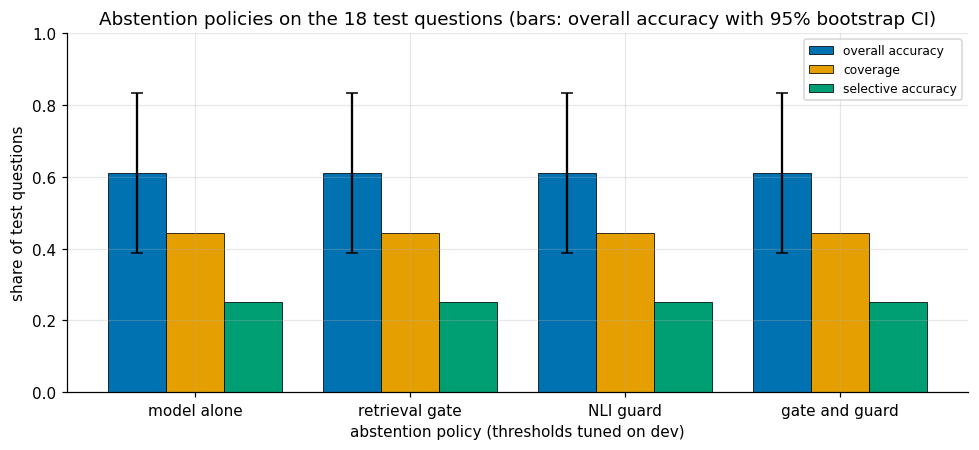

> On the test split, no dev-tuned policy beat the model's own refusals: the model alone reached overall accuracy 0.61 (95% CI 0.39 to 0.83) at 44% coverage.

In [15]:
def bootstrap_policy(frame: pd.DataFrame, abstain: pd.Series, n: int = N_BOOT, seed: int = SEED) -> tuple:
    """95% bootstrap interval of overall accuracy over test questions."""
    right = np.where(abstain, ~frame.answerable, frame.answerable & frame.correct).astype(float)
    idx = np.random.default_rng(seed).integers(0, len(right), size=(n, len(right)))
    boot = right[idx].mean(axis=1)
    return float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))


ci = {name: bootstrap_policy(test_df, apply_policy(test_df, g, t)) for name, (g, t) in policies.items()}
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(policies))
w = 0.27
for j, (metric, colour) in enumerate([("overall accuracy", "#0072B2"), ("coverage", "#E69F00"), ("selective accuracy", "#009E73")]):
    ax.bar(x + (j - 1) * w, results[metric], width=w, color=colour, label=metric, edgecolor="black", linewidth=0.5)
ax.errorbar(x - w, results["overall accuracy"], yerr=[results["overall accuracy"] - [ci[p][0] for p in policies],
                                                       [ci[p][1] for p in policies] - results["overall accuracy"]],
            fmt="none", ecolor="black", capsize=4)
ax.set_xticks(x)
ax.set_xticklabels(list(policies))
ax.set_ylim(0, 1)
ax.set_xlabel("abstention policy (thresholds tuned on dev)")
ax.set_ylabel("share of test questions")
ax.set_title(f"Abstention policies on the {len(test_df)} test questions (bars: overall accuracy with 95% bootstrap CI)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
base_acc = results.loc["model alone", "overall accuracy"]
best_policy = results["overall accuracy"].idxmax()  # ties keep the first, i.e. the simpler policy
if results.loc[best_policy, "overall accuracy"] > base_acc:
    policy_text = (f"`{best_policy}` has the highest overall accuracy, {results.loc[best_policy, 'overall accuracy']:.2f} "
                   f"(95% CI {ci[best_policy][0]:.2f} to {ci[best_policy][1]:.2f}) at {results.loc[best_policy, 'coverage']:.0%} coverage, "
                   f"against {base_acc:.2f} at {results.loc['model alone', 'coverage']:.0%} coverage for the model alone")
else:
    policy_text = (f"no dev-tuned policy beat the model's own refusals: the model alone reached overall accuracy {base_acc:.2f} "
                   f"(95% CI {ci['model alone'][0]:.2f} to {ci['model alone'][1]:.2f}) at {results.loc['model alone', 'coverage']:.0%} coverage")
takeaway(f"On the test split, {policy_text}.")

In [16]:
# Cover image for the Kaggle listing: the risk-coverage curves at 1280 x 720 pixels
fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=100)
plot_curves(ax, gen_df, big=True)
ax.set_title("When should a RAG system answer? Accuracy against coverage for four confidence signals", fontsize=17)
ax.xaxis.label.set_fontsize(15)
ax.yaxis.label.set_fontsize(15)
ax.tick_params(labelsize=13)
fig.tight_layout()
fig.savefig(WORK_DIR / "cover.png", dpi=100)
plt.close(fig)
print(f"notebook run time so far: {(time.time() - NOTEBOOK_START) / 60:.1f} min")

notebook run time so far: 22.8 min


## 9. What we found

In [17]:
best_auc = auc.stack().idxmax()
mode_note = f" (FAST smoke-test mode: {len(gen_df)} questions)" if FAST else ""
findings = [
    f"Before any generation, the {best_auc[0]} separated answerable from unanswerable questions best, with AUROC {auc.loc[best_auc]:.2f} on the {best_auc[1].lower()}; "
    f"the top-1 cosine alone reached {auc.loc['top-1 cosine', 'Consumer rules']:.2f} on the rules and {auc.loc['top-1 cosine', 'CS / AI textbooks']:.2f} on the textbooks.",
    f"`{GENERATOR.split('/')[-1]}` refused {gen_df[~gen_df.answerable]['model abstained'].mean():.0%} of unanswerable questions on its own and wrongly refused "
    f"{gen_df[gen_df.answerable]['model abstained'].mean():.0%} of answerable ones{mode_note}.",
    f"Among confidence signals for ranking its answers, `{ranked[0]}` gave the largest area under the accuracy-coverage curve ({areas[ranked[0]]:.3f}, random {areas['random']:.3f}).",
    f"On the test split, {policy_text}.",
]
display(Markdown("\n\n".join(findings)))

Before any generation, the rerank score separated answerable from unanswerable questions best, with AUROC 0.95 on the consumer rules; the top-1 cosine alone reached 0.91 on the rules and 0.88 on the textbooks.

`Qwen2.5-0.5B-Instruct` refused 89% of unanswerable questions on its own and wrongly refused 11% of answerable ones (FAST smoke-test mode: 36 questions).

Among confidence signals for ranking its answers, `answer log-prob` gave the largest area under the accuracy-coverage curve (0.214, random 0.123).

On the test split, no dev-tuned policy beat the model's own refusals: the model alone reached overall accuracy 0.61 (95% CI 0.39 to 0.83) at 44% coverage.

### Limitations

The test split has about 100 questions and the dev split about 50, so dev-tuned thresholds are noisy and the test intervals are wide. Correctness is an NLI judgement against a one-line gold answer, which misses correct answers phrased differently and can accept a vague answer that happens to entail it. The unanswerable questions were generated to sit near the documents' topics; real users also ask off-topic questions, which a similarity gate rejects far more easily. A 1.5B generator refuses and cites differently from the larger models people deploy, so the policy ranking may change with the model.

### Ideas to try

- Swap `GENERATOR` for `Qwen/Qwen2.5-3B-Instruct` (check its licence first) and see whether the model's own refusals improve.
- Tune the gate for a target false-abstention rate instead of overall accuracy.
- Combine the four signals with a logistic regression trained on dev.
- Ask the model to rate its own confidence and add that as a fifth signal.

### The VeriDex series

1. [Chunking legal text for RAG: structure-aware vs fixed vs semantic chunks](https://www.kaggle.com/code/swapnilshukla007/chunking-legal-text-for-rag)
2. [BM25, dense, RRF fusion and cross-encoder reranking: a retrieval ablation you can rerun](https://www.kaggle.com/code/swapnilshukla007/bm25-dense-rrf-and-reranking-rag-ablation)
3. [Catching unsupported sentences: NLI faithfulness checks for RAG answers](https://www.kaggle.com/code/swapnilshukla007/nli-faithfulness-checks-for-rag-answers)
4. Teaching a RAG system to abstain (this notebook)
5. [RAG in a browser tab: int8 embedding indexes and the size-recall trade-off](https://www.kaggle.com/code/swapnilshukla007/rag-in-a-browser-tab-int8-embedding-indexes)

If you spot a mistake or get different numbers, please say so in the comments; an upvote helps other people find the notebook.